# Symmetrical chokes example


In [3]:
import sys
import os
from pathlib import Path
sys.path.insert(0, str(os.path.dirname(os.path.dirname(Path.cwd())) + "/src"))

In this example the MPC model is fitted to a 4-port s-parameters obtained from a CMC choke measurement. We read the s-parameters with a custom minimal `read_s4p` function.

In [5]:
from cmc_mpc import read_s4p

f, S, z0 = read_s4p("../../ltspice/presets/MPC_choke1_python.s4p")

S.shape

(601, 4, 4)

There are 601 frequency points, and the matrix at each of the frequency point is $4\times4$ to there are all the combinations of the 4-port parameters $S_{ij}$.

To understand if the MCP model can be used on this data, we first perform a quick check on the reciprocity of the s-parameters: $S_{ij} \approx S_{ji}$.

In [6]:
import matplotlib.pyplot as plt
import numpy as np


errors = np.zeros((4, 4), dtype=np.float64)

for i in range(0, 4):
    for j in range(0, 4):
        errors[i, j] = np.abs((S[:,i,j] - S[:,j,i]).sum(), dtype=np.float64)
errors


array([[0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 1.00005043e-12],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 9.99999996e-13],
       [0.00000000e+00, 1.00005043e-12, 9.99999996e-13, 0.00000000e+00]])

The difference between $S_{ij}$ and $S_{ji}$ are very small, therefore we can assume that the choke is quite symmetrical, and also use only a portion of the S-parameters. We can plot the important s-parameters. In particular we will use $S_{11}, S_{21}, S_{31}$ and $S_{41}$, i.e. the first column of the $S$ matrix.

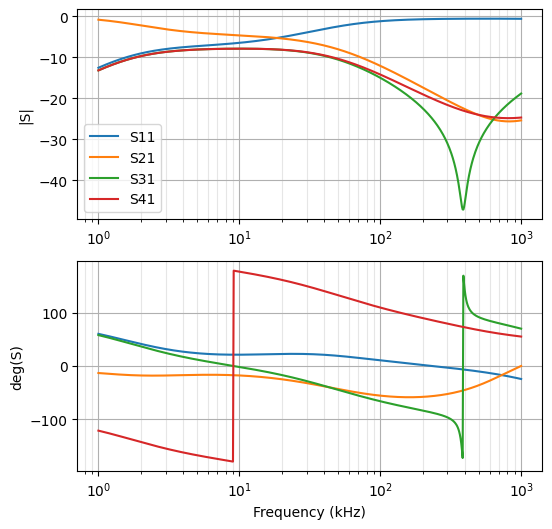

In [9]:
s_11 = S[:,0,0]; s_21 = S[:,1,0]; s_31 = S[:,2,0]; s_41 = S[:,3,0]

fig, (ax1, ax2) = plt.subplots(figsize=(6,6), ncols=1, nrows=2)

for i in range(0, 4):
    ax1.semilogx(f/1e6, 20*np.log10(np.abs(S[:,i,0])))
ax1.grid()
ax1.grid(which='minor', color="0.9")
ax1.set(ylabel="|S|")
ax1.legend(['S11','S21', 'S31', 'S41'])


for i in range(0, 4):
    ax2.semilogx(f/1e6, np.rad2deg(np.angle(S[:,i,0])))
ax2.grid()
ax2.grid(which='minor', color="0.9")
ax2.set(xlabel="Frequency (kHz)", ylabel="deg(S)")

plt.show()

The behaviour of the s-parameters for a choke is quite predictable.


Now, let's have a look at modal admittances of this choke. In particular, we look into four modal admittances:

1. $Y_G$ - the admittance of the component-to-ground. This admittance can be very small, and almost negligible.
2. $Y_W$ - the interwinding admittance, i.e. the admittance between the windings of the choke.
3. $Y_D$ - the differential mode admittance.
4. $Y_C$ - the common mode admittance. 

In order to get these modes, we first obtain the modal admittances $Y$ in port basis by $Y = (I+S)^{-1}(I-S)/R.$

Due to the symmetry of the choke the solutions in the modal basis is the diagonal of $Y_{\text{mod}},$ where $Y_{\text{mod}} = E^{-1} Y E / 4$ and $E$ are the eigenvectors of the modal basis. The matrix multiplication is computed per frequency point. 

In [27]:
from cmc_mpc.setups import y_from_s

E = np.array([
        [1, 1, 1, 1],
        [1, -1, 1, -1],
        [1, 1, -1, -1],
        [1, -1, -1, 1],
        ], dtype=np.float64)
E_INV = np.linalg.inv(E)

Y = y_from_s(S, R=z0) # the modal matrix in the port basis
Y_mod = np.einsum('ij,njk,kl->nil', E_INV, Y, E)


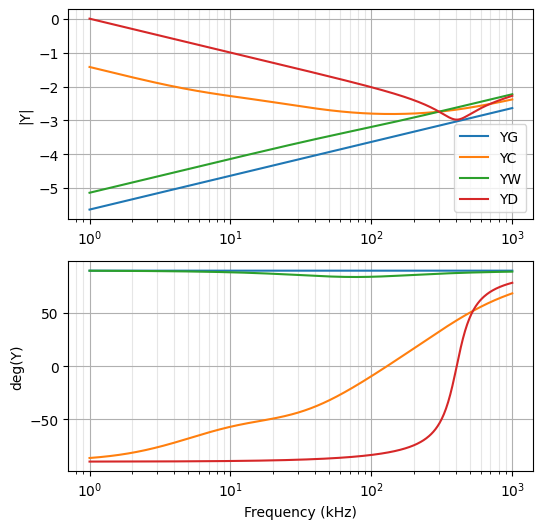

In [28]:
YG = Y_mod[:,0,0]; YC = Y_mod[:,1,1]; YW = Y_mod[:,2,2]; YD = Y_mod[:,3,3]

fig, (ax1, ax2) = plt.subplots(figsize=(6,6), ncols=1, nrows=2)

for i in range(0, 4):
    ax1.semilogx(f/1e6, np.log10(np.abs(Y_mod[:,i,i])))
ax1.grid()
ax1.grid(which='minor', color="0.9")
ax1.set(ylabel="|Y|")
ax1.legend(['YG', 'YC', 'YW', 'YD'])

for i in range(0, 4):
    ax2.semilogx(f/1e6, np.rad2deg(np.angle(Y_mod[:,i,i])))
ax2.grid()
ax2.grid(which='minor', color="0.9")
ax2.set(xlabel="Frequency (kHz)", ylabel="deg(Y)")

plt.show()

In our code, obtaining the modal admittances is achieved by creating the `FourPort` object. 

In [37]:
from cmc_mpc import FourPort

mpc_fp = FourPort(f, S, z0)

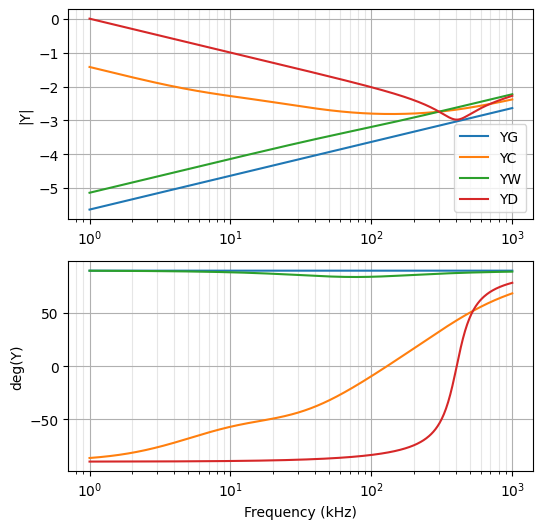

In [38]:
fig, (ax1, ax2) = plt.subplots(figsize=(6,6), ncols=1, nrows=2)

for mode in ('G', 'C', 'W', 'D'):
    ax1.semilogx(f/1e6, np.log10(np.abs(mpc_fp.data[mode])))
ax1.grid()
ax1.grid(which='minor', color="0.9")
ax1.set(ylabel="|Y|")
ax1.legend(['YG', 'YC', 'YW', 'YD'])


for mode in ('G', 'C', 'W', 'D'):
    ax2.semilogx(f/1e6, np.rad2deg(np.angle(mpc_fp.data[mode])))
ax2.grid()
ax2.grid(which='minor', color="0.9")
ax2.set(xlabel="Frequency (kHz)", ylabel="deg(Y)")

plt.show()

Having the modal admittances we want to fit the MPC model to the data. We do it by calling the function `fit` from `cmp_mpc`.

The object that we pass on is the `FourPort` network, and we can select which of the optional higher-order variants of the MPC we fit: `lcr_w` is the LCR tank for the interwinding admittance, `cr` stands for the C-R parallel branch of the CM part, `rl` is the R-L parallel branch of the CM part, `cg` are the capacitances to ground which correspond to the `YG` admittance (G mode). 

In [39]:
from cmc_mpc import Variant, fit

result = fit(mpc_fp, Variant(lcr_w=True, cr=1, rl=1, cg=True))
print(result.report())


method least_squares, cost 1.132e-08, 38.7 s
best cost reached by 27 of 50 starts
  LC       8.274e-06  log-std   0.00496  determined
  CC       1.302e-13  log-std   0.00735  determined
  RC        6.35e+08  log-std  7.99e+04  NOT determined
  LD       3.132e-07  log-std  0.000857  determined
  CD       3.127e-13  log-std   0.00303  determined
  RD            1896  log-std   0.00285  determined
  CW       7.886e-13  log-std     0.101  determined
  Lw          0.0001  log-std      21.6  NOT determined  AT BOUND
  Cwt       2.11e-12  log-std     0.269  determined
  Rw           779.4  log-std     0.532  weak
  Rcr           1316  log-std     0.166  determined
  Ccr      7.188e-11  log-std     0.315  weak
  Rrl           1063  log-std    0.0164  determined
  Lrl      1.041e-05  log-std   0.00715  determined
  Cg       3.687e-13  log-std    0.0037  determined


The results show the values of the MPC model. We can save it to and LTSpice netlist. 

In [42]:
from cmc_mpc.ltspice import write_ltspice

sub_path, s4p_path = write_ltspice(result.params, outdir='.', tag='01_example_choke_symmetrical')

In [46]:
with open(sub_path) as file:
    sub_netlist = file.readlines()
    print(str(''.join(line for line in sub_netlist)))
file.close()

* MPC model, generated by cmc_mpc.ltspice from circuit.mpc_netlist
* Inductor dots sit at the first node of each inductor.
.subckt MPC_01_example_choke_symmetrical port1 port2 port3 port4 params:
+ LC=8.27399e-06 CC=1.30207e-13 RC=6.34967e+08 LD=3.13177e-07 CD=3.12733e-13 RD=1895.94 CW=7.88559e-13 Lw=0.0001 Cwt=2.1096e-12 Rw=779.435 Rcr=1315.72 Ccr=7.18772e-11 Rrl=1062.57 Lrl=1.04104e-05 Cg=3.68706e-13
Lc1 port1 a1 {LC/2}
Lc3 port3 a3 {LC/2}
Cc1 port1 a1 {CC}
Rc1 port1 a1 {RC}
Rcr1_0 port1 xcr1_0 {Rcr}
Ccr1_0 xcr1_0 a1 {Ccr}
Rrl1_0 port1 xrl1_0 {Rrl}
Lrl1_0 xrl1_0 a1 {Lrl}
Cc3 port3 a3 {CC}
Rc3 port3 a3 {RC}
Rcr3_0 port3 xcr3_0 {Rcr}
Ccr3_0 xcr3_0 a3 {Ccr}
Rrl3_0 port3 xrl3_0 {Rrl}
Lrl3_0 xrl3_0 a3 {Lrl}
Ld1 a1 m1 {LD/8}
Ld2 m1 port2 {LD/8}
Ld3 m3 a3 {LD/8}
Ld4 port4 m3 {LD/8}
Cd1 a1 port2 {CD}
Rd1 a1 port2 {RD}
Cd3 a3 port4 {CD}
Rd3 a3 port4 {RD}
Cw m1 w1 {CW}
Lw w1 m3 {Lw}
Cwt w1 m3 {Cwt}
Rw w1 m3 {Rw}
Cg1 port1 0 {Cg}
Cg2 port2 0 {Cg}
Cg3 port3 0 {Cg}
Cg4 port4 0 {Cg}
K1 Lc1 Lc3 1
K

This subcircuit can be included in the LTspice simulation.

Let's now have a look at the comparison between the s4p parameters obtained form this MPC fit, and the VNA original data.

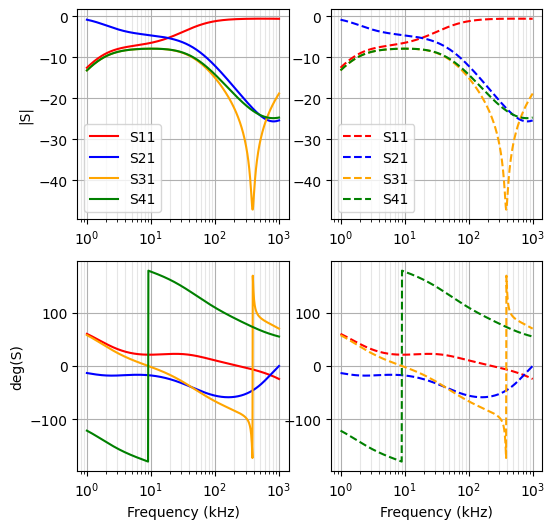

In [56]:
f, mpc_s4p, z0 = read_s4p(s4p_path)

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(
    figsize=(6, 6), ncols=2, nrows=2
)

colors = ('red', 'blue', 'orange', 'green')

for i in range(0, 4):
    ax1.semilogx(f/1e6, 20*np.log10(np.abs(S[:,i,0])), '-',
                 color=colors[i])
    ax2.semilogx(f/1e6, 20*np.log10(np.abs(mpc_s4p[:,i,0])), '--', 
                 color=colors[i])
ax1.grid()
ax1.grid(which='minor', color="0.9")
ax1.set(ylabel="|S|")
ax1.legend(['S11','S21', 'S31', 'S41'])

ax2.grid()
ax2.grid(which='minor', color="0.9")
ax2.legend(['S11','S21', 'S31', 'S41'])


for i in range(0, 4):
    ax3.semilogx(f/1e6, np.rad2deg(np.angle(S[:,i,0])), '-',
                 color=colors[i])
    ax4.semilogx(f/1e6, np.rad2deg(np.angle(mpc_s4p[:,i,0])), '--',
                 color=colors[i])
ax3.grid()
ax3.grid(which='minor', color="0.9")
ax3.set(xlabel="Frequency (kHz)", ylabel="deg(S)")

ax4.grid()
ax4.grid(which='minor', color="0.9")
ax4.set(xlabel="Frequency (kHz)")

plt.show()


The s-parameters of the MPC fit are the same as the original VNA s-parameters, and therefore the fit is confirmed. An independent verification can be performed with LTSpice.